In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("flights.csv", low_memory=False)

In [4]:
df.shape

(5819079, 31)

In [5]:
df.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              object 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          object 
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24

In [7]:
df.isnull().sum()

YEAR                         0
MONTH                        0
DAY                          0
DAY_OF_WEEK                  0
AIRLINE                      0
FLIGHT_NUMBER                0
TAIL_NUMBER              14721
ORIGIN_AIRPORT               0
DESTINATION_AIRPORT          0
SCHEDULED_DEPARTURE          0
DEPARTURE_TIME           86153
DEPARTURE_DELAY          86153
TAXI_OUT                 89047
WHEELS_OFF               89047
SCHEDULED_TIME               6
ELAPSED_TIME            105071
AIR_TIME                105071
DISTANCE                     0
WHEELS_ON                92513
TAXI_IN                  92513
SCHEDULED_ARRIVAL            0
ARRIVAL_TIME             92513
ARRIVAL_DELAY           105071
DIVERTED                     0
CANCELLED                    0
CANCELLATION_REASON    5729195
AIR_SYSTEM_DELAY       4755640
SECURITY_DELAY         4755640
AIRLINE_DELAY          4755640
LATE_AIRCRAFT_DELAY    4755640
WEATHER_DELAY          4755640
dtype: int64

In [8]:
(df.isnull().sum() / len(df)*100).round(2)

YEAR                    0.00
MONTH                   0.00
DAY                     0.00
DAY_OF_WEEK             0.00
AIRLINE                 0.00
FLIGHT_NUMBER           0.00
TAIL_NUMBER             0.25
ORIGIN_AIRPORT          0.00
DESTINATION_AIRPORT     0.00
SCHEDULED_DEPARTURE     0.00
DEPARTURE_TIME          1.48
DEPARTURE_DELAY         1.48
TAXI_OUT                1.53
WHEELS_OFF              1.53
SCHEDULED_TIME          0.00
ELAPSED_TIME            1.81
AIR_TIME                1.81
DISTANCE                0.00
WHEELS_ON               1.59
TAXI_IN                 1.59
SCHEDULED_ARRIVAL       0.00
ARRIVAL_TIME            1.59
ARRIVAL_DELAY           1.81
DIVERTED                0.00
CANCELLED               0.00
CANCELLATION_REASON    98.46
AIR_SYSTEM_DELAY       81.72
SECURITY_DELAY         81.72
AIRLINE_DELAY          81.72
LATE_AIRCRAFT_DELAY    81.72
WEATHER_DELAY          81.72
dtype: float64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
print("Cancelled Flights:")
print(df["CANCELLED"].value_counts())
print("\nDiverted Flights:")
print(df["DIVERTED"].value_counts())

Cancelled Flights:
CANCELLED
0    5729195
1      89884
Name: count, dtype: int64

Diverted Flights:
DIVERTED
0    5803892
1      15187
Name: count, dtype: int64


In [11]:
df["AIRLINE"].value_counts()

AIRLINE
WN    1261855
DL     875881
AA     725984
OO     588353
EV     571977
UA     515723
MQ     294632
B6     267048
US     198715
AS     172521
NK     117379
F9      90836
HA      76272
VX      61903
Name: count, dtype: int64

In [12]:
df["AIRLINE"].nunique()

14

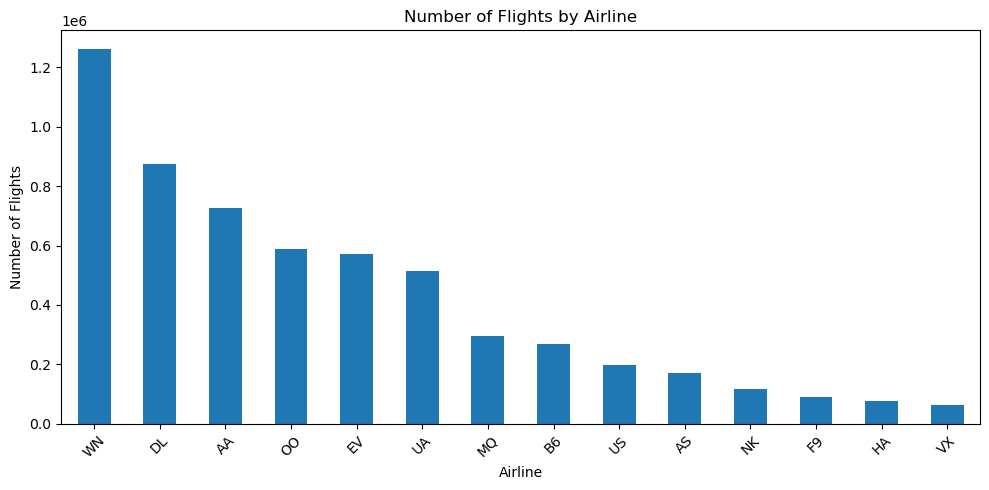

In [13]:
import matplotlib.pyplot as plt
airline_counts = df["AIRLINE"].value_counts()
plt.figure(figsize=(10, 5))
airline_counts.plot(kind="bar")
plt.title("Number of Flights by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
df["AIRLINE"].unique()

array(['AS', 'AA', 'US', 'DL', 'NK', 'UA', 'HA', 'B6', 'OO', 'EV', 'MQ',
       'F9', 'WN', 'VX'], dtype=object)

In [15]:
airline_names = {
    "AS": "Alaska Airlines",
    "AA": "American Airlines",
    "US": "US Airways",
    "DL": "Delta Air Lines",
    "NK": "Spirit Airlines",
    "UA": "United Airlines",
    "HA": "Hawaiian Airlines",
    "B6": "JetBlue Airways",
    "OO": "SkyWest Airlines",
    "EV": "ExpressJet Airlines",
    "MQ": "Envoy Air",
    "F9": "Frontier Airlines",
    "WN": "Southwest Airlines",
    "VX": "Virgin America"
}
df["AIRLINE_NAME"] = df["AIRLINE"].map(airline_names)

In [16]:
df[["AIRLINE", "AIRLINE_NAME"]].head(10)

,AIRLINE,AIRLINE_NAME
0,AS,Alaska Airlines
1,AA,American Airlines
2,US,US Airways
3,AA,American Airlines
4,AS,Alaska Airlines
5,DL,Delta Air Lines
6,NK,Spirit Airlines
7,US,US Airways
8,AA,American Airlines
9,DL,Delta Air Lines


In [17]:
avg_departure_delay = (
    df.groupby("AIRLINE_NAME")["DEPARTURE_DELAY"]
    .mean()
    .sort_values(ascending=False)
)
avg_departure_delay

AIRLINE_NAME
Spirit Airlines        15.944766
United Airlines        14.435441
Frontier Airlines      13.350858
JetBlue Airways        11.514353
Southwest Airlines     10.581986
Envoy Air              10.125188
Virgin America          9.022595
American Airlines       8.900856
ExpressJet Airlines     8.715934
SkyWest Airlines        7.801104
Delta Air Lines         7.369254
US Airways              6.141137
Alaska Airlines         1.785801
Hawaiian Airlines       0.485713
Name: DEPARTURE_DELAY, dtype: float64

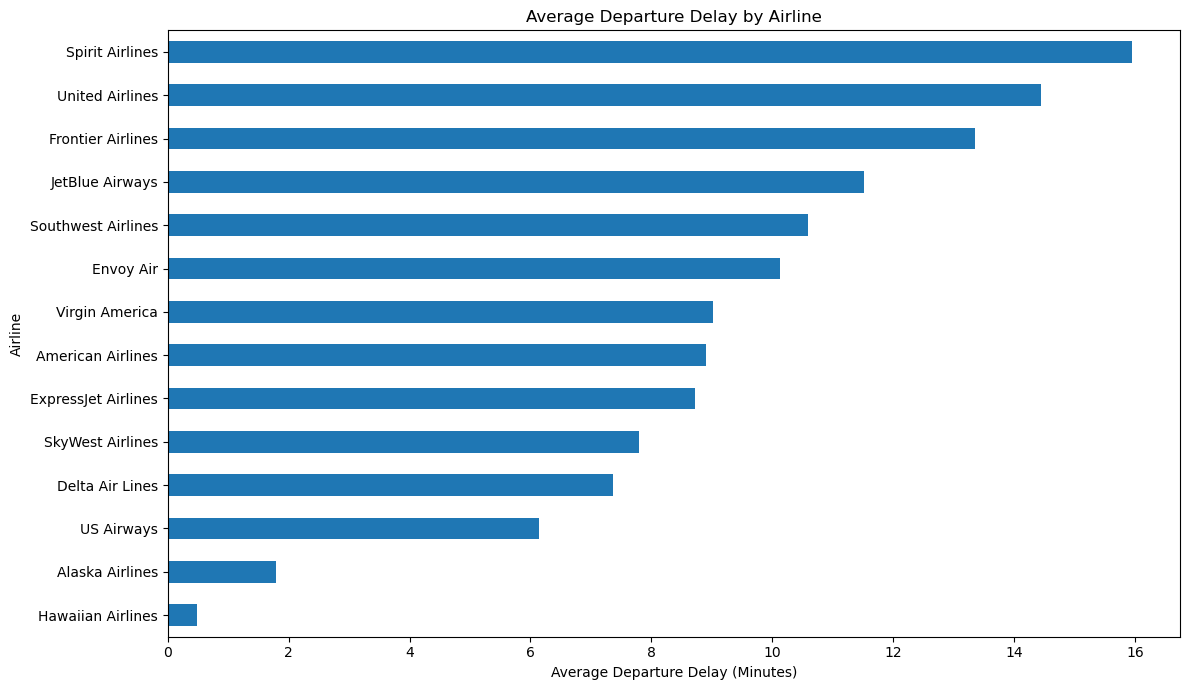

In [18]:
plt.figure(figsize=(12, 7))
avg_departure_delay.sort_values().plot(kind="barh")
plt.title("Average Departure Delay by Airline")
plt.xlabel("Average Departure Delay (Minutes)")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

In [19]:
avg_arrival_delay = (
    df.groupby("AIRLINE_NAME")["ARRIVAL_DELAY"]
    .mean()
    .sort_values(ascending=False)
)
avg_arrival_delay

AIRLINE_NAME
Spirit Airlines        14.471800
Frontier Airlines      12.504706
JetBlue Airways         6.677861
ExpressJet Airlines     6.585379
Envoy Air               6.457873
SkyWest Airlines        5.845652
United Airlines         5.431594
Virgin America          4.737706
Southwest Airlines      4.374964
US Airways              3.706209
American Airlines       3.451372
Hawaiian Airlines       2.023093
Delta Air Lines         0.186754
Alaska Airlines        -0.976563
Name: ARRIVAL_DELAY, dtype: float64

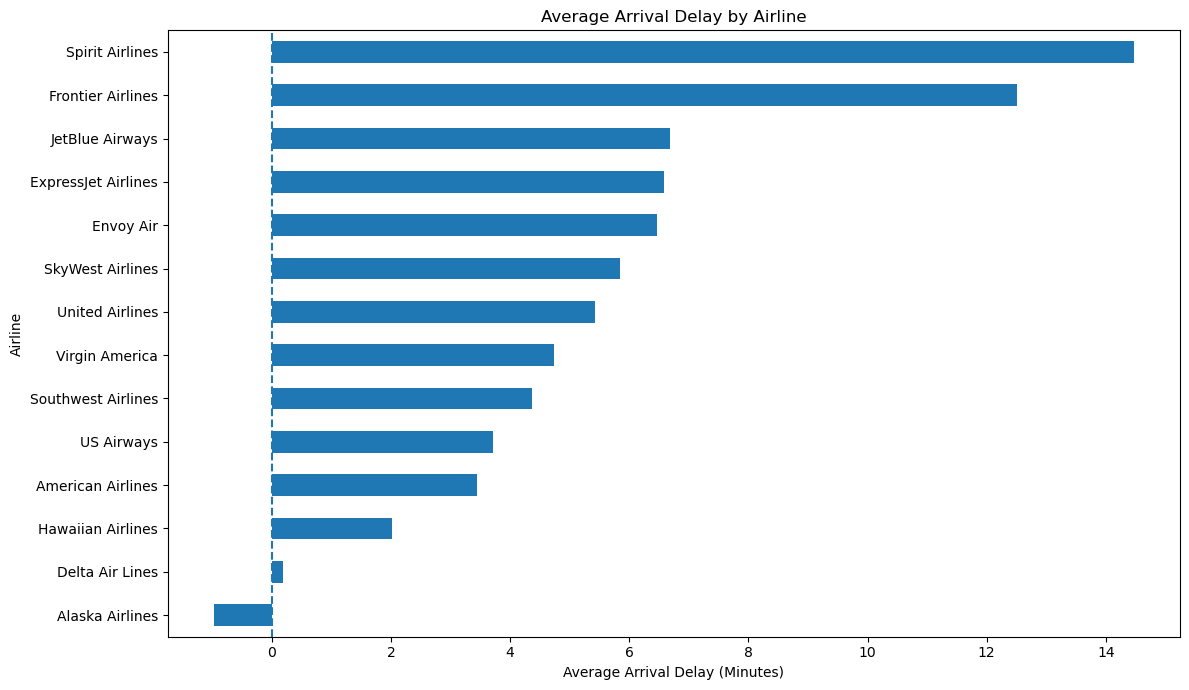

In [20]:
plt.figure(figsize=(12, 7))
avg_arrival_delay.sort_values().plot(kind="barh")
plt.title("Average Arrival Delay by Airline")
plt.xlabel("Average Arrival Delay (Minutes)")
plt.ylabel("Airline")
plt.axvline(x=0, linestyle="--")
plt.tight_layout()
plt.show()

In [21]:
airline_delay_comparison = pd.DataFrame({
    "Average_Departure_Delay": avg_departure_delay,
    "Average_Arrival_Delay": avg_arrival_delay
})
airline_delay_comparison

,Average_Departure_Delay,Average_Arrival_Delay
AIRLINE_NAME,,
Alaska Airlines,1.785801,-0.976563
American Airlines,8.900856,3.451372
Delta Air Lines,7.369254,0.186754
Envoy Air,10.125188,6.457873
ExpressJet Airlines,8.715934,6.585379
Frontier Airlines,13.350858,12.504706
Hawaiian Airlines,0.485713,2.023093
JetBlue Airways,11.514353,6.677861
SkyWest Airlines,7.801104,5.845652


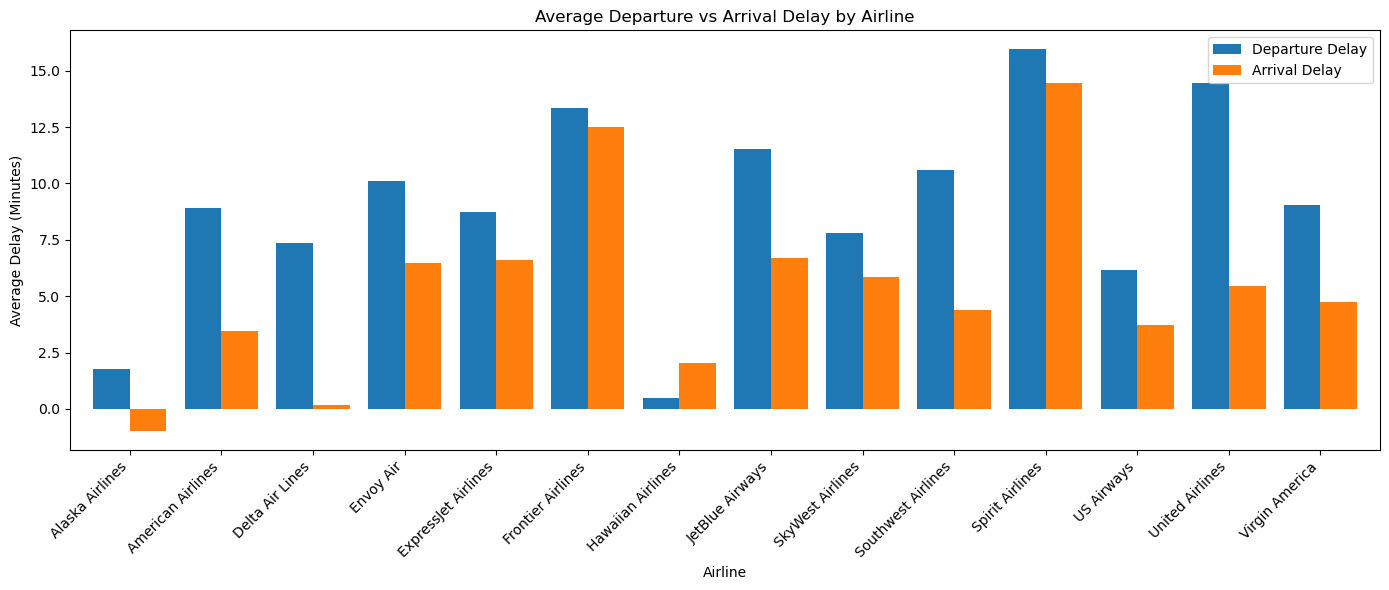

In [22]:
airline_delay_comparison.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)
plt.title("Average Departure vs Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=45, ha="right")
plt.legend(["Departure Delay", "Arrival Delay"])
plt.tight_layout()
plt.show()

In [23]:
monthly_delay = df.groupby("MONTH")["DEPARTURE_DELAY"].mean()
monthly_delay

MONTH
1      9.759471
2     11.885284
3      9.660903
4      7.721885
5      9.454144
6     13.986016
7     11.394664
8      9.932045
9      4.823560
10     4.982661
11     6.944197
12    11.783529
Name: DEPARTURE_DELAY, dtype: float64

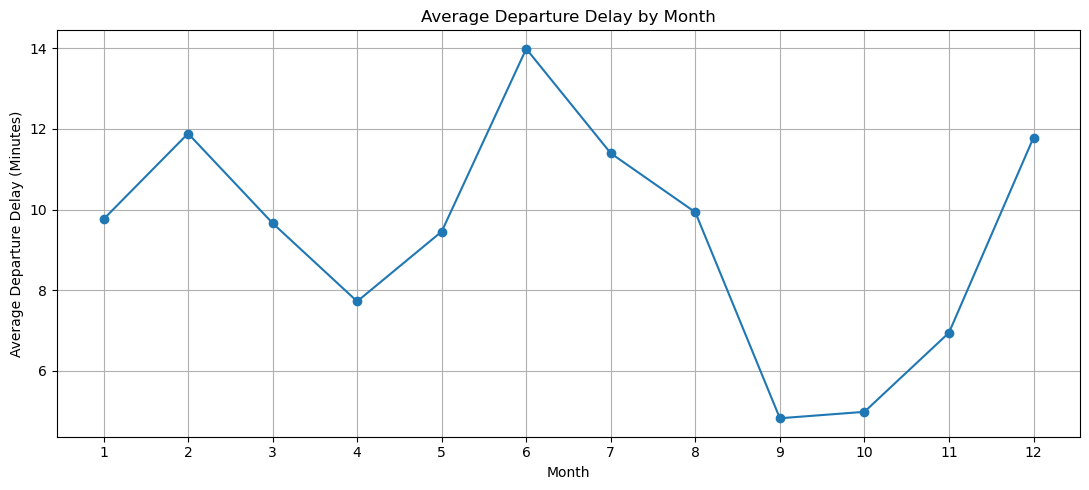

In [24]:
plt.figure(figsize=(11, 5))
monthly_delay.plot(kind="line", marker="o")
plt.title("Average Departure Delay by Month")
plt.xlabel("Month")
plt.ylabel("Average Departure Delay (Minutes)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
monthly_arrival_delay = (
    df.groupby("MONTH")["ARRIVAL_DELAY"]
    .mean()
)
monthly_arrival_delay

MONTH
1     5.813583
2     8.320500
3     4.920673
4     3.163190
5     4.485019
6     9.601590
7     6.431775
8     4.607372
9    -0.772571
10   -0.780390
11    1.100784
12    6.092903
Name: ARRIVAL_DELAY, dtype: float64

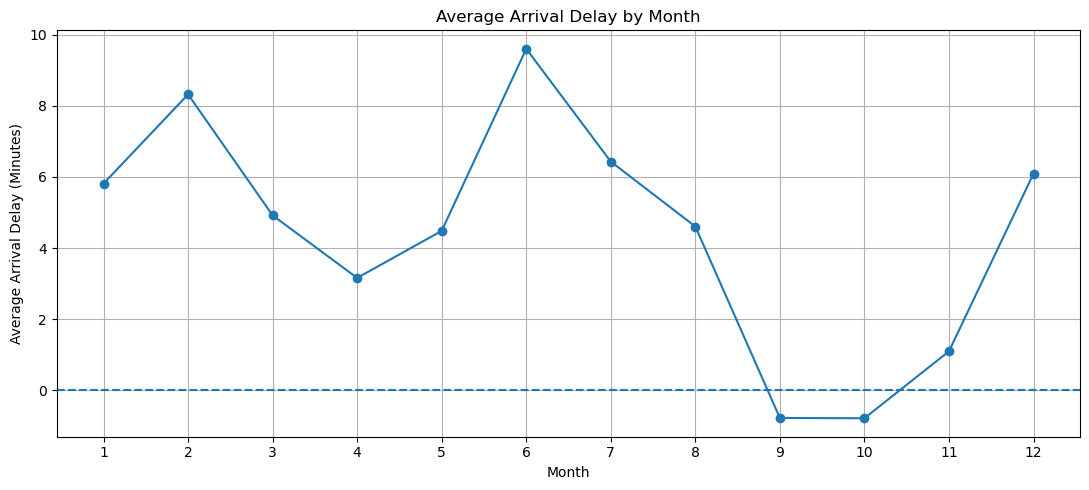

In [26]:
plt.figure(figsize=(11, 5))
monthly_arrival_delay.plot(kind="line", marker="o")
plt.title("Average Arrival Delay by Month")
plt.xlabel("Month")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(range(1, 13))
plt.axhline(y=0, linestyle="--")
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
monthly_delay_comparison = pd.DataFrame({
    "Departure_Delay": monthly_delay,
    "Arrival_Delay": monthly_arrival_delay
})
monthly_delay_comparison

,Departure_Delay,Arrival_Delay
MONTH,,
1,9.759471,5.813583
2,11.885284,8.320500
3,9.660903,4.920673
4,7.721885,3.163190
5,9.454144,4.485019
6,13.986016,9.601590
7,11.394664,6.431775
8,9.932045,4.607372
9,4.823560,-0.772571


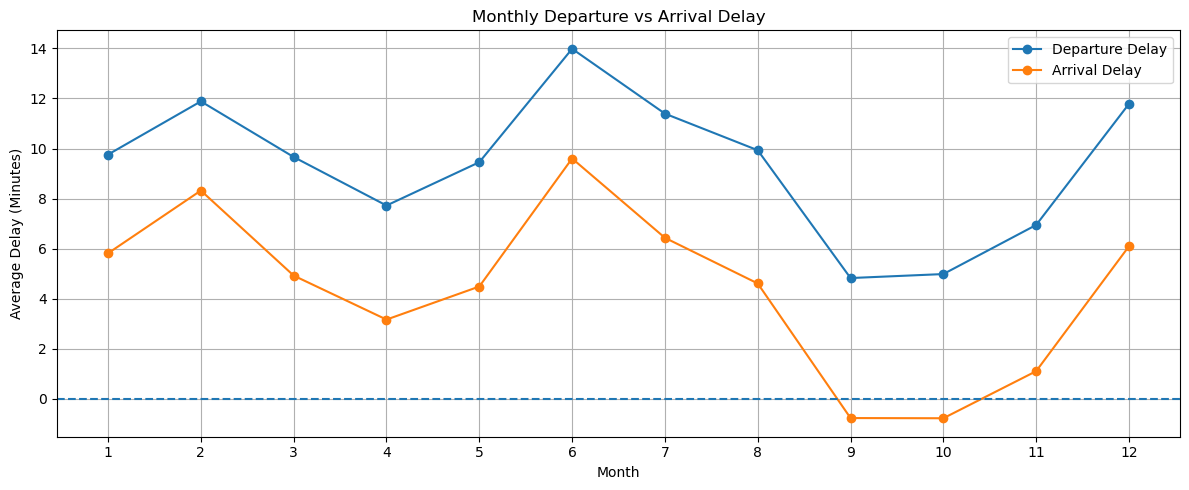

In [28]:
monthly_delay_comparison.plot(kind="line",figsize=(12, 5),marker="o")
plt.title("Monthly Departure vs Arrival Delay")
plt.xlabel("Month")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(range(1, 13))
plt.axhline(y=0, linestyle="--")
plt.legend(["Departure Delay", "Arrival Delay"])
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
weekly_delay = df.groupby("DAY_OF_WEEK")["DEPARTURE_DELAY"].mean()
weekly_delay

DAY_OF_WEEK
1    10.871775
2     9.164522
3     8.645277
4     9.956913
5     9.429768
6     7.827416
7     9.402856
Name: DEPARTURE_DELAY, dtype: float64

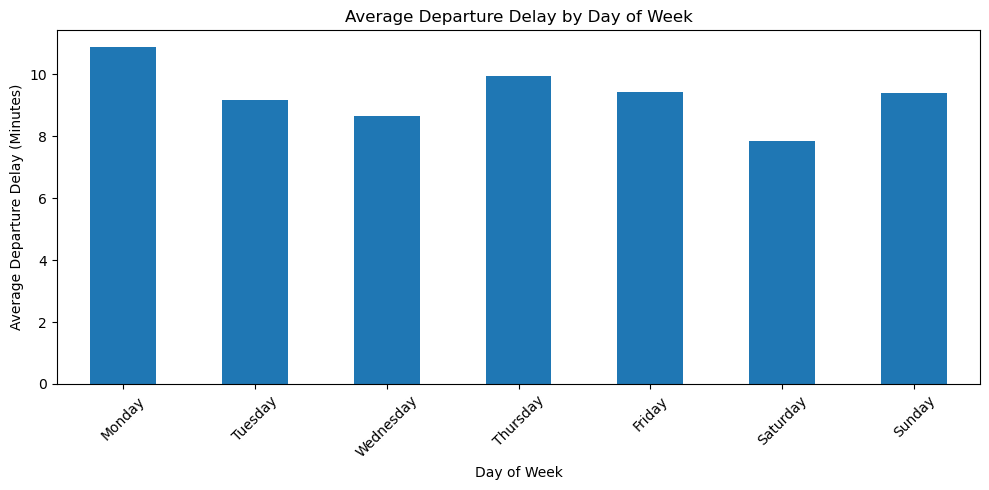

In [30]:
day_names = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}
weekly_delay.index = weekly_delay.index.map(day_names)
plt.figure(figsize=(10, 5))
weekly_delay.plot(kind="bar")
plt.title("Average Departure Delay by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Departure Delay (Minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
weekly_arrival_delay = (
    df.groupby("DAY_OF_WEEK")["ARRIVAL_DELAY"]
    .mean()
)
weekly_arrival_delay.index = weekly_arrival_delay.index.map(day_names)
weekly_arrival_delay

DAY_OF_WEEK
Monday       6.002063
Tuesday      4.246041
Wednesday    3.845468
Thursday     5.668334
Friday       4.764079
Saturday     1.852892
Sunday       3.958293
Name: ARRIVAL_DELAY, dtype: float64

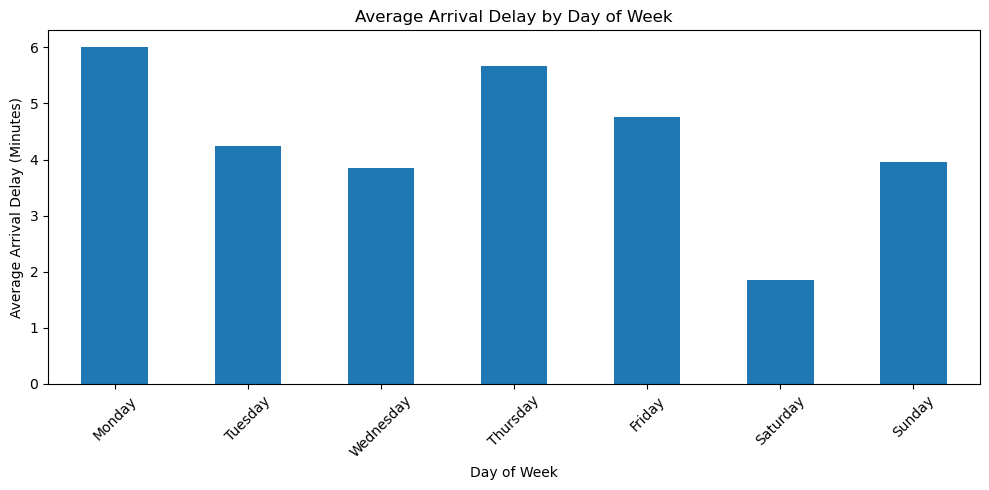

In [32]:
plt.figure(figsize=(10, 5))
weekly_arrival_delay.plot(kind="bar")
plt.title("Average Arrival Delay by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
weekly_delay_comparison = pd.DataFrame({
    "Departure_Delay": weekly_delay,
    "Arrival_Delay": weekly_arrival_delay
})
weekly_delay_comparison

,Departure_Delay,Arrival_Delay
DAY_OF_WEEK,,
Monday,10.871775,6.002063
Tuesday,9.164522,4.246041
Wednesday,8.645277,3.845468
Thursday,9.956913,5.668334
Friday,9.429768,4.764079
Saturday,7.827416,1.852892
Sunday,9.402856,3.958293


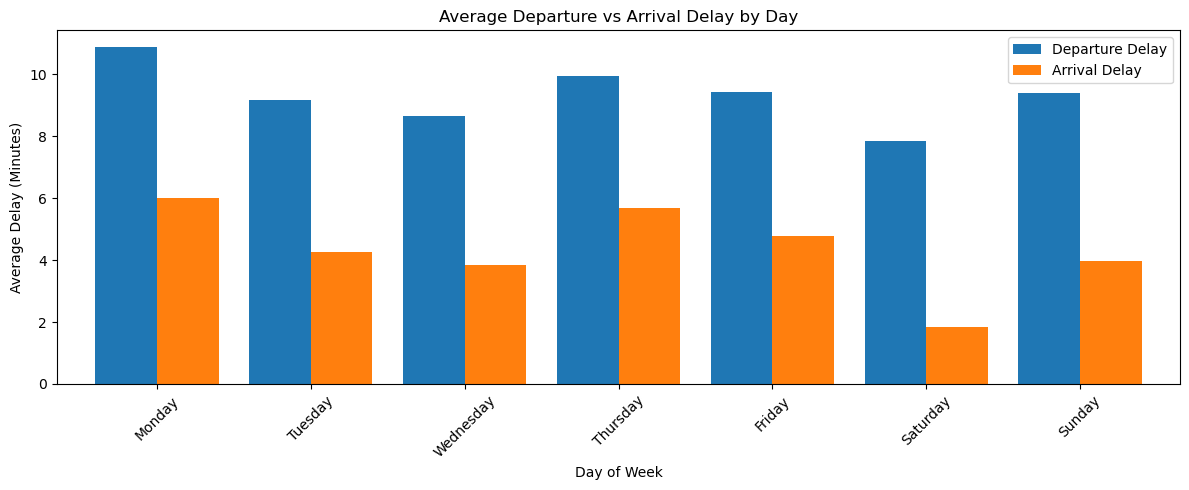

In [34]:
weekly_delay_comparison.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)
plt.title("Average Departure vs Arrival Delay by Day")
plt.xlabel("Day of Week")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=45)
plt.legend(["Departure Delay", "Arrival Delay"])
plt.tight_layout()
plt.show()

In [35]:
top_origin_airports = df["ORIGIN_AIRPORT"].value_counts().head(10)
top_origin_airports

ORIGIN_AIRPORT
ATL    346836
ORD    285884
DFW    239551
DEN    196055
LAX    194673
SFO    148008
PHX    146815
IAH    146622
LAS    133181
MSP    112117
Name: count, dtype: int64

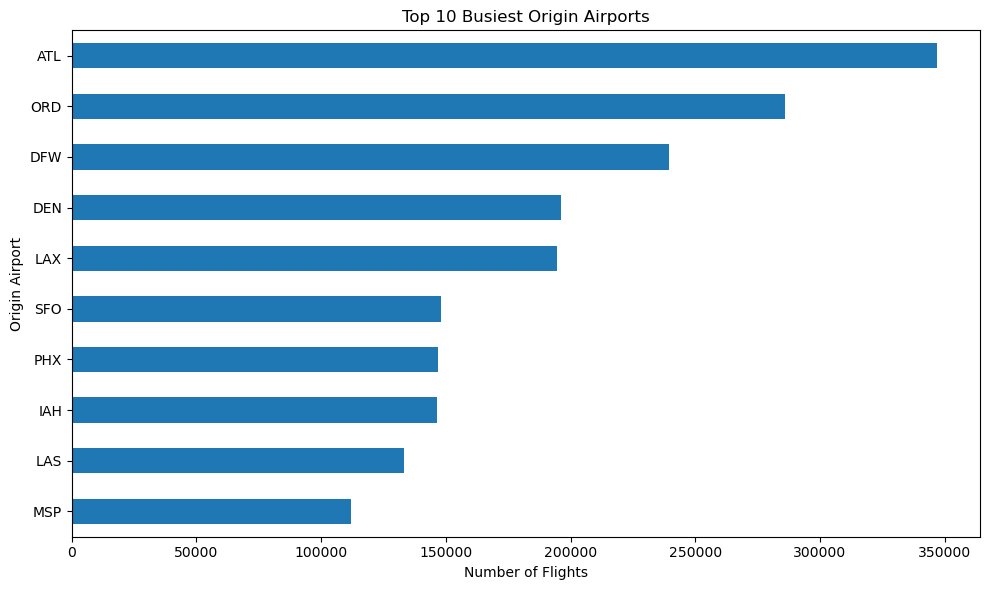

In [36]:
plt.figure(figsize=(10, 6))
top_origin_airports.sort_values().plot(kind="barh")
plt.title("Top 10 Busiest Origin Airports")
plt.xlabel("Number of Flights")
plt.ylabel("Origin Airport")
plt.tight_layout()
plt.show()

In [38]:
top_destination_airports = (
    df["DESTINATION_AIRPORT"].value_counts().head(10)
)
top_destination_airports

DESTINATION_AIRPORT
ATL    346904
ORD    285906
DFW    239582
DEN    196010
LAX    194696
SFO    147966
PHX    146812
IAH    146683
LAS    133198
MSP    112128
Name: count, dtype: int64

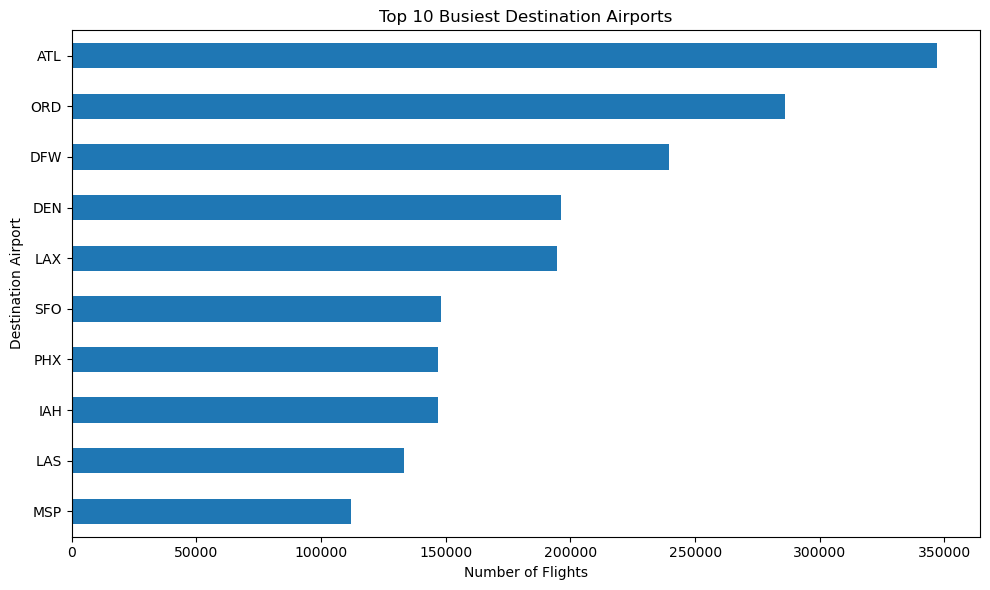

In [39]:
plt.figure(figsize=(10, 6))
top_destination_airports.sort_values().plot(kind="barh")
plt.title("Top 10 Busiest Destination Airports")
plt.xlabel("Number of Flights")
plt.ylabel("Destination Airport")
plt.tight_layout()
plt.show()

In [40]:
delay_columns = [
    "AIR_SYSTEM_DELAY",
    "SECURITY_DELAY",
    "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "WEATHER_DELAY"
]
delay_reasons = df[delay_columns].sum().sort_values(ascending=False)
delay_reasons

LATE_AIRCRAFT_DELAY    24961931.0
AIRLINE_DELAY          20172956.0
AIR_SYSTEM_DELAY       14335762.0
WEATHER_DELAY           3100233.0
SECURITY_DELAY            80985.0
dtype: float64

In [41]:
delay_reasons.index = [
    "Airline",
    "Late Aircraft",
    "Air System",
    "Weather",
    "Security"
]

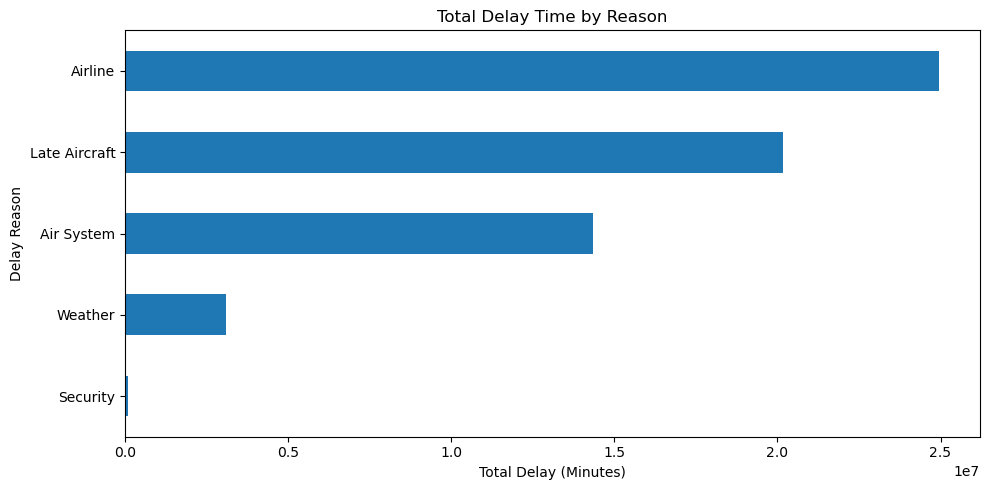

In [42]:
plt.figure(figsize=(10, 5))
delay_reasons.sort_values().plot(kind="barh")
plt.title("Total Delay Time by Reason")
plt.xlabel("Total Delay (Minutes)")
plt.ylabel("Delay Reason")
plt.tight_layout()
plt.show()

In [43]:
cancellation_reasons = df["CANCELLATION_REASON"].value_counts()
cancellation_reasons

CANCELLATION_REASON
B    48851
A    25262
C    15749
D       22
Name: count, dtype: int64

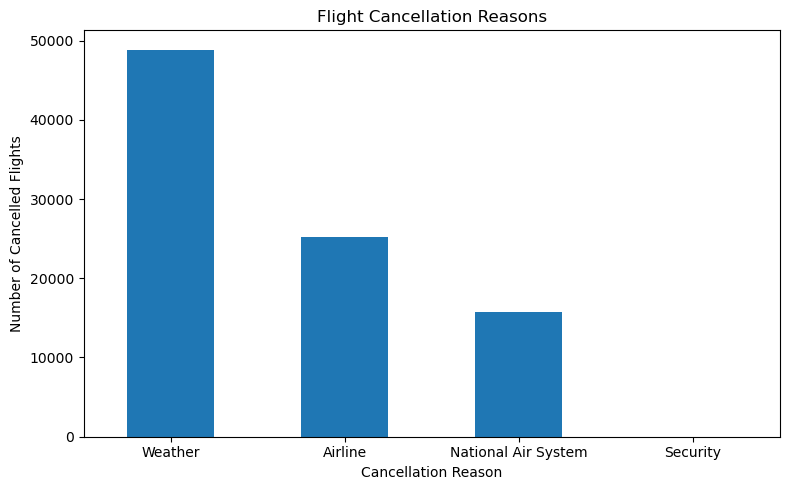

In [44]:
cancellation_names = {
    "A": "Airline",
    "B": "Weather",
    "C": "National Air System",
    "D": "Security"
}
cancellation_reasons.index = cancellation_reasons.index.map(
    cancellation_names
)
plt.figure(figsize=(8, 5))
cancellation_reasons.plot(kind="bar")
plt.title("Flight Cancellation Reasons")
plt.xlabel("Cancellation Reason")
plt.ylabel("Number of Cancelled Flights")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [45]:
total_flights = len(df)
cancelled_flights = df["CANCELLED"].sum()
diverted_flights = df["DIVERTED"].sum()
avg_departure_delay = df["DEPARTURE_DELAY"].mean()
avg_arrival_delay = df["ARRIVAL_DELAY"].mean()
delayed_departures = (df["DEPARTURE_DELAY"] > 0).sum()
print("Total Flights:", total_flights)
print("Cancelled Flights:", cancelled_flights)
print("Diverted Flights:", diverted_flights)
print("Average Departure Delay:", round(avg_departure_delay, 2))
print("Average Arrival Delay:", round(avg_arrival_delay, 2))
print("Flights with Departure Delay:", delayed_departures)

Total Flights: 5819079
Cancelled Flights: 89884
Diverted Flights: 15187
Average Departure Delay: 9.37
Average Arrival Delay: 4.41
Flights with Departure Delay: 2125618


In [46]:
cancellation_percentage = (
    cancelled_flights / total_flights
) * 100
diversion_percentage = (
    diverted_flights / total_flights
) * 100
departure_delay_percentage = (
    delayed_departures / total_flights
) * 100
print("Cancellation Percentage:", round(cancellation_percentage, 2), "%")
print("Diversion Percentage:", round(diversion_percentage, 2), "%")
print("Departure Delay Percentage:", round(departure_delay_percentage, 2), "%")

Cancellation Percentage: 1.54 %
Diversion Percentage: 0.26 %
Departure Delay Percentage: 36.53 %


In [47]:
print("HIGHEST DEPARTURE DELAY AIRLINE:")
print(avg_departure_delay_by_airline if False else
      df.groupby("AIRLINE_NAME")["DEPARTURE_DELAY"].mean().idxmax())
print("\nHIGHEST ARRIVAL DELAY AIRLINE:")
print(df.groupby("AIRLINE_NAME")["ARRIVAL_DELAY"].mean().idxmax())
print("\nHIGHEST DEPARTURE DELAY MONTH:")
print(df.groupby("MONTH")["DEPARTURE_DELAY"].mean().idxmax())
print("\nHIGHEST ARRIVAL DELAY MONTH:")
print(df.groupby("MONTH")["ARRIVAL_DELAY"].mean().idxmax())
print("\nBUSIEST ORIGIN AIRPORT:")
print(df["ORIGIN_AIRPORT"].value_counts().idxmax())
print("\nBUSIEST DESTINATION AIRPORT:")
print(df["DESTINATION_AIRPORT"].value_counts().idxmax())

HIGHEST DEPARTURE DELAY AIRLINE:
Spirit Airlines

HIGHEST ARRIVAL DELAY AIRLINE:
Spirit Airlines

HIGHEST DEPARTURE DELAY MONTH:
6

HIGHEST ARRIVAL DELAY MONTH:
6

BUSIEST ORIGIN AIRPORT:
ATL

BUSIEST DESTINATION AIRPORT:
ATL
